# Introduction au Quantum Machine Learning avec Qiskit
**Auteur : Serge Alain KAMENAN** · notebook d'accompagnement du cours *Introduction au Quantum Machine Learning avec Qiskit*

Objectif : construire deux classifieurs quantiques (VQC et QSVC) sur le jeu de données Iris, puis les comparer honnêtement à des modèles classiques.

Testé avec Qiskit 2.6, Qiskit Machine Learning 0.9 et scikit-learn, sur simulateur (aucun accès à une vraie machine n'est nécessaire).

## 0. Installation
À exécuter une seule fois si les bibliothèques ne sont pas installées (dans Google Colab, par exemple).

In [14]:
# !pip install qiskit qiskit-machine-learning scikit-learn matplotlib pylatexenc

In [15]:
import time
import numpy as np
import matplotlib.pyplot as plt
import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Statevector
print("Qiskit", qiskit.__version__, "| Qiskit Machine Learning", qiskit_machine_learning.__version__)

Qiskit 2.6.1 | Qiskit Machine Learning 0.9.1


## 1. Rappels : superposition, intrication, mesure
### 1.1 Un qubit en superposition
La porte H met le qubit dans une superposition égale de 0 et 1. On mesure 1 024 fois (*shots*).

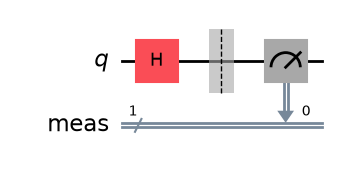

Résultats : {'1': 509, '0': 515}


In [16]:
qc = QuantumCircuit(1)
qc.h(0)
qc.measure_all()
display(qc.draw("mpl"))

sampler = StatevectorSampler(seed=42)
resultat = sampler.run([qc], shots=1024).result()
comptes = resultat[0].data.meas.get_counts()
print("Résultats :", comptes)

On obtient environ 512 fois `0` et 512 fois `1` : la mesure révèle les probabilités |α|² et |β|².

### 1.2 Deux qubits intriqués : l'état de Bell
H puis CNOT : les deux qubits donnent toujours le même résultat.

Probabilités : {'00': 0.5, '11': 0.5}


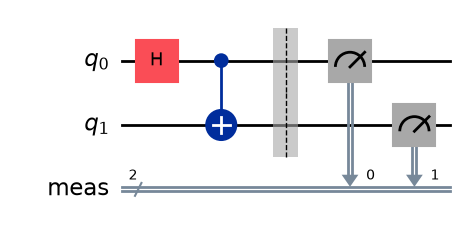

Résultats : {'11': 509, '00': 515}


In [17]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
print("Probabilités :", {str(k): round(float(v), 3) for k, v in Statevector(bell).probabilities_dict().items()})
bell.measure_all()
display(bell.draw("mpl"))
print("Résultats :", sampler.run([bell], shots=1024).result()[0].data.meas.get_counts())

Seuls `00` et `11` apparaissent : c'est l'intrication. Les résultats `01` et `10` sont impossibles.

## 2. Les données : Iris
150 fleurs, 4 mesures (longueur et largeur des sépales et des pétales), 3 espèces.

**Normalisation dans [0, π]** : les variables deviendront des angles de rotation, qui sont périodiques.

In [18]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

X, y = load_iris(return_X_y=True)
X = MinMaxScaler(feature_range=(0, np.pi)).fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=42, stratify=y)
print("Entraînement :", X_train.shape, "| Test :", X_test.shape)
print("Première fleur (angles en radians) :", X_train[0].round(3))

Entraînement : (120, 4) | Test : (30, 4)
Première fleur (angles en radians) : [0.087 1.178 0.213 0.131]


## 3. Encoder les données dans un circuit
### 3.1 Encodage par angle, construit à la main
Chaque variable pilote une rotation RY sur son propre qubit.

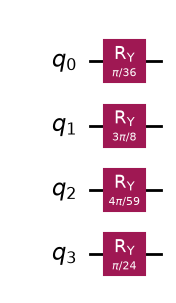

5 états les plus probables : {'0000': 0.679, '0010': 0.303, '0100': 0.008, '0110': 0.003, '1000': 0.003}
Attention : Qiskit lit les bits de droite à gauche (le qubit 0 est le dernier caractère).


In [19]:
def encodage_angle(x):
    qc = QuantumCircuit(len(x))
    for i, valeur in enumerate(x):
        qc.ry(valeur, i)
    return qc

circuit = encodage_angle(X_train[0])
display(circuit.draw("mpl"))
probas = Statevector(circuit).probabilities_dict()
top = sorted(probas.items(), key=lambda kv: -kv[1])[:5]
print("5 états les plus probables :", {str(k): round(float(v), 3) for k, v in top})
print("Attention : Qiskit lit les bits de droite à gauche (le qubit 0 est le dernier caractère).")

### 3.2 La ZZFeatureMap
Elle ajoute des couplages entre qubits, et donc de l'intrication : elle représente les interactions entre variables.

Nombre de paramètres (les 4 variables) : 4


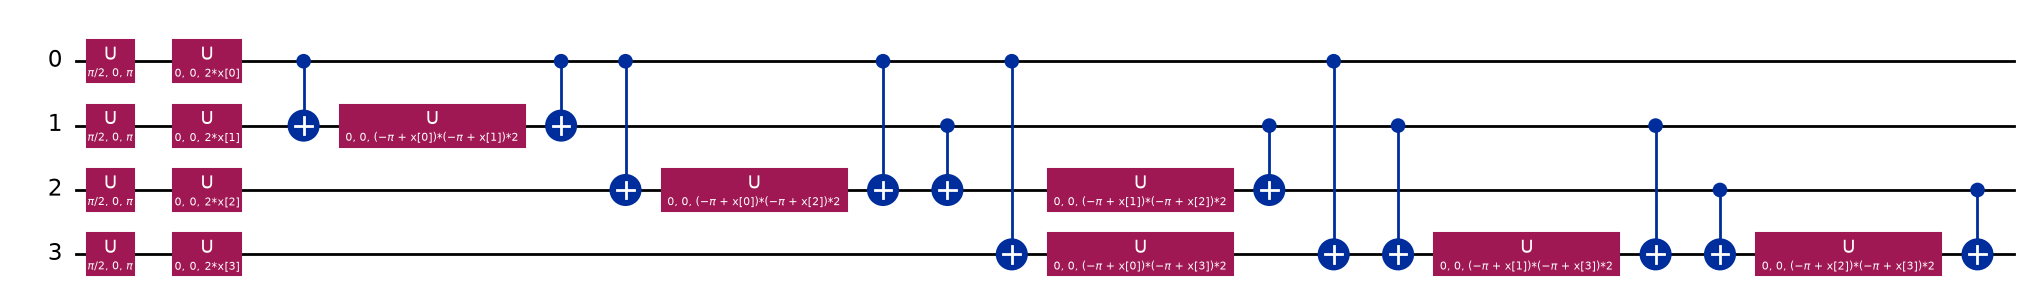

In [20]:
from qiskit.circuit.library import zz_feature_map

feature_map = zz_feature_map(feature_dimension=4, reps=1)
print("Nombre de paramètres (les 4 variables) :", feature_map.num_parameters)
display(feature_map.decompose().draw("mpl", fold=40))

## 4. Le classifieur variationnel (VQC)
Un circuit = **encodage** (les données) + **ansatz** (les paramètres appris θ). Un optimiseur classique ajuste θ pour réduire l'erreur : c'est la **boucle hybride**.

Paramètres à apprendre : 12


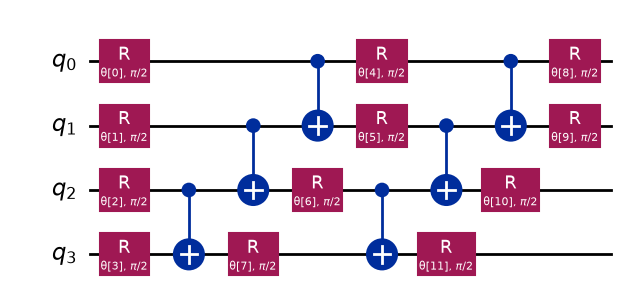

In [21]:
from qiskit.circuit.library import real_amplitudes

ansatz = real_amplitudes(num_qubits=4, reps=2)
print("Paramètres à apprendre :", ansatz.num_parameters)
display(ansatz.decompose().draw("mpl", fold=40))




In [22]:
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.optimizers import COBYLA

historique = []
def suivi(poids, valeur_objectif):
    historique.append(valeur_objectif)

vqc = VQC(
    sampler=StatevectorSampler(seed=42),
    feature_map=feature_map,
    ansatz=ansatz,
    optimizer=COBYLA(maxiter=100),
    initial_point=np.random.default_rng(42).uniform(0, 2 * np.pi, ansatz.num_parameters),
    callback=suivi,
)
debut = time.time()
vqc.fit(X_train, y_train)
print(f"Entraînement terminé en {time.time() - debut:.0f} s")
score_vqc_train = vqc.score(X_train, y_train)
score_vqc_test = vqc.score(X_test, y_test)
print(f"VQC  précision entraînement : {score_vqc_train:.2f} | test : {score_vqc_test:.2f}")

Entraînement terminé en 59 s
VQC  précision entraînement : 0.53 | test : 0.60


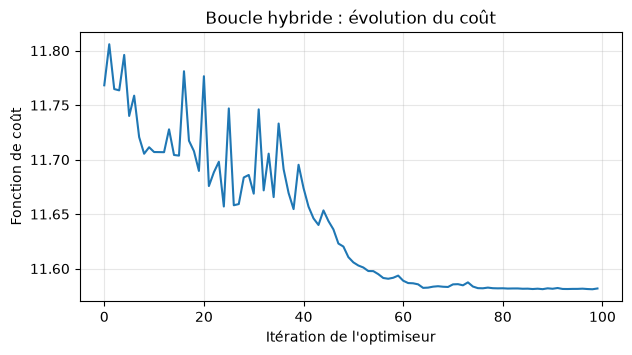

In [23]:
plt.figure(figsize=(7, 3.5))
plt.plot(historique)
plt.xlabel("Itération de l'optimiseur")
plt.ylabel("Fonction de coût")
plt.title("Boucle hybride : évolution du coût")
plt.grid(alpha=0.3)
plt.show()

## 5. Les noyaux quantiques et la QSVC
On ne fait plus apprendre le circuit : on l'utilise pour mesurer la **ressemblance** entre deux fleurs,

k(x, x') = |⟨φ(x)|φ(x')⟩|²,

puis une SVM classique fait la classification avec ces ressemblances.

Matrice de noyau 30 x 30 calculée en 2 s


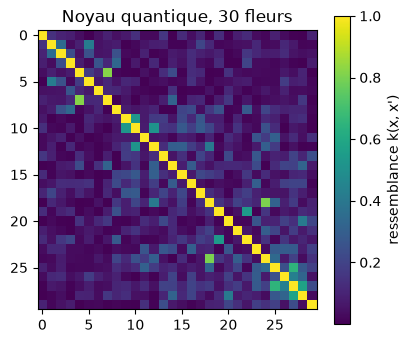

In [24]:
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.algorithms import QSVC

noyau = FidelityQuantumKernel(feature_map=zz_feature_map(feature_dimension=4, reps=1))
debut = time.time()
matrice = noyau.evaluate(x_vec=X_train[:30])
print(f"Matrice de noyau 30 x 30 calculée en {time.time() - debut:.0f} s")

ordre = np.argsort(y_train[:30])
plt.figure(figsize=(4.5, 4))
plt.imshow(matrice[np.ix_(ordre, ordre)], cmap="viridis")
plt.colorbar(label="ressemblance k(x, x')")
plt.title("Noyau quantique, 30 fleurs")
plt.show()

La diagonale vaut 1 (chaque fleur ressemble parfaitement à elle-même), mais les ressemblances entre fleurs différentes restent faibles, même au sein d'une espèce. Ce noyau est très « pointu » : il distingue bien les points, au risque de trop coller aux données d'entraînement. Diminuer l'échelle des angles (par exemple [0, π/2]) adoucit le noyau : c'est l'objet de l'exercice 5.

In [25]:
qsvc = QSVC(quantum_kernel=noyau)
debut = time.time()
qsvc.fit(X_train, y_train)
print(f"Entraînement terminé en {time.time() - debut:.0f} s")
score_qsvc_train = qsvc.score(X_train, y_train)
score_qsvc_test = qsvc.score(X_test, y_test)
print(f"QSVC précision entraînement : {score_qsvc_train:.2f} | test : {score_qsvc_test:.2f}")

Entraînement terminé en 34 s
QSVC précision entraînement : 1.00 | test : 0.97


## 6. Comparer honnêtement avec le classique
Un modèle quantique n'a d'intérêt que s'il fait au moins aussi bien qu'un modèle classique simple, sur les mêmes données.

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
import pandas as pd

logit = LogisticRegression(max_iter=1000).fit(X_train, y_train)
svm = SVC(kernel="rbf").fit(X_train, y_train)

resultats = pd.DataFrame({
    "Modèle": ["VQC (quantique)", "QSVC (quantique)", "Régression logistique", "SVM classique (RBF)"],
    "Précision entraînement": [score_vqc_train, score_qsvc_train, logit.score(X_train, y_train), svm.score(X_train, y_train)],
    "Précision test": [score_vqc_test, score_qsvc_test, logit.score(X_test, y_test), svm.score(X_test, y_test)],
}).round(2)
resultats

,Modèle,Précision entraînement,Précision test
0,VQC (quantique),0.53,0.60
1,QSVC (quantique),1.00,0.97
2,Régression logistique,0.96,0.93
3,SVM classique (RBF),0.98,0.97


### Conclusion
- La **QSVC** atteint le niveau des modèles classiques : le noyau quantique fonctionne.
- Le **VQC** fait nettement moins bien avec ces réglages : le coût baisse peu puis stagne, signe qu'un circuit simple de 12 paramètres et 100 itérations ne suffit pas pour séparer 3 classes. C'est une difficulté connue des circuits variationnels.
- Sur des données aussi simples, **aucun avantage quantique** n'est attendu : le but est d'apprendre la méthode, pas de battre le classique.

### Exercices
1. Passez `COBYLA(maxiter=100)` à 300 : la précision du VQC s'améliore-t-elle ?
2. Remplacez `real_amplitudes(reps=2)` par `reps=4`. Plus de paramètres aide-t-il, ou ralentit-il seulement ?
3. Ne gardez que 2 espèces (`y != 2`) : le VQC devient-il compétitif ?
4. Remplacez la ZZFeatureMap par votre encodage par angle dans `FidelityQuantumKernel` : que devient la QSVC ?
5. Normalisez les données dans [0, π/2] au lieu de [0, π] : comment évoluent la carte du noyau et la précision de test ?